# 1. Your first batch

This notebook runs one batch of the simulated 100 m³ penicillin fermenter, looks at the results, compares a few
batches and saves the data. Every other tutorial builds on what you see here.

**You need:** Penicillium and matplotlib (`pip install -e ".[notebooks]"` from a clone of the repository).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})

import penicillium
from penicillium import Simulator

print("Penicillium", penicillium.__version__)

Penicillium 0.1.0.dev0


## Run a batch

`Simulator().run(seed=...)` simulates a complete 230 h batch: 1150 samples of 12 minutes, following IndPenSim's
default feeding recipe, with the pH and temperature loops in automatic. The seed fixes the batch's random initial
conditions, kinetic parameters and slow disturbances, so the same seed always gives the same batch.

In [2]:
result = Simulator().run(seed=1)

print(
    f"Samples:              {len(result)} (every {result.time[1] - result.time[0]:.1f} h up to {result.time[-1]:.0f} h)"
)
print(f"Harvested penicillin: {result.total_yield:.0f} kg")
print(f"Final titre:          {result['P'][-1]:.1f} g/L")
print(f"Final broth volume:   {result['V'][-1] / 1000:.1f} m³")

Samples:              1150 (every 0.2 h up to 230 h)
Harvested penicillin: 3602 kg
Final titre:          30.8 g/L
Final broth volume:   78.8 m³


`result.total_yield` is the **harvested** penicillin: what is in the vessel at the end plus what the periodic broth
draws removed during the batch. `result[name]` returns one channel as a NumPy array and `result.time` the matching
times in hours. The full list of channels and units is in [Variables and units](../variables.md).

## As a DataFrame

In [3]:
df = result.to_pandas()  # index: time_h, one column per channel
print(df.shape)
df[["P", "X", "S", "DO2", "PAA", "T", "pH", "V"]].iloc[::200].round(3)

(1150, 55)


,P,X,S,DO2,PAA,T,pH,V
time_h,,,,,,,,
0.2,0.001,0.482,0.825,14.629,1314.477,297.537,6.484,57477.999
40.2,3.102,14.466,0.002,12.689,267.631,298.094,6.496,60642.964
80.2,11.978,20.689,0.001,14.115,899.344,298.342,6.525,79968.993
120.2,19.549,23.537,0.000,12.368,1175.201,297.906,6.514,82535.720
160.2,25.620,23.835,0.001,11.700,1677.679,297.887,6.512,76339.779
200.2,29.980,22.622,0.001,11.195,2210.002,297.892,6.490,75288.717


Units: penicillin `P`, biomass `X` and substrate `S` in g/L; dissolved oxygen `DO2` and `PAA` in mg/L; temperature
`T` in K; volume `V` in L.

## Plot the batch

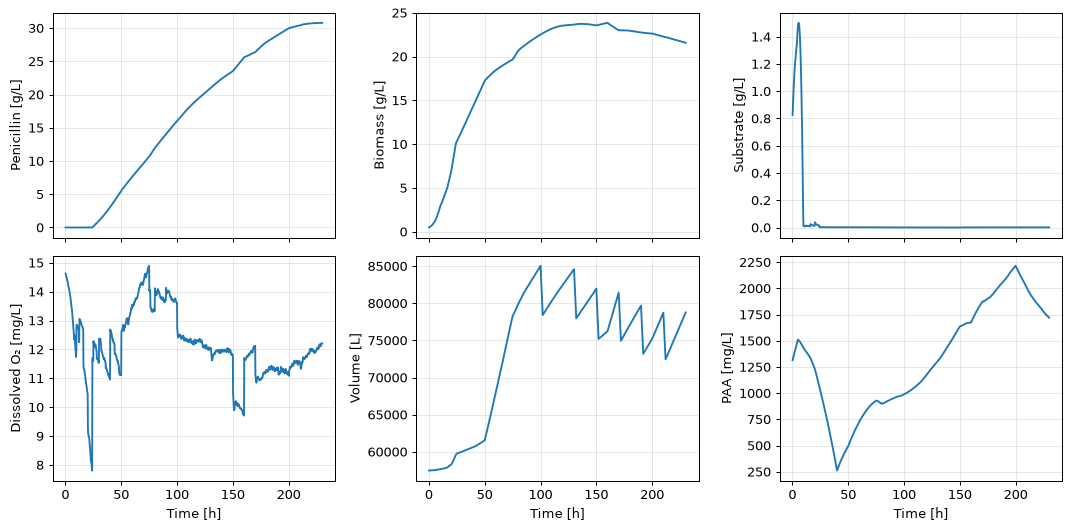

In [4]:
panels = [
    ("P", "Penicillin [g/L]"),
    ("X", "Biomass [g/L]"),
    ("S", "Substrate [g/L]"),
    ("DO2", "Dissolved O₂ [mg/L]"),
    ("V", "Volume [L]"),
    ("PAA", "PAA [mg/L]"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
for ax, (name, label) in zip(axes.flat, panels):
    ax.plot(result.time, result[name])
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
fig.tight_layout()

What the plot shows:

- **Biomass** grows quickly during the first ~40 h and then levels off once the sugar feed limits growth.
- **Substrate** falls to a few mg/L within a day and stays there: in the model, penicillin is produced only at very
  low sugar concentrations, so the recipe feeds sugar just fast enough to sustain the culture.
- **Penicillin** appears after about a day and rises almost linearly.
- **Volume** rises with the feeds and drops by about 8 m³ at each harvest draw (from 100 h).
- **PAA**, the side-chain precursor, is consumed with production and topped up by the PAA feed.

[The process](../process.md) describes the phases of a batch in detail.

## The inputs

The recipe sets the feeds, aeration and back pressure; the pH and temperature controllers set acid, base, cooling and
heating flows. All of them are recorded as channels too.

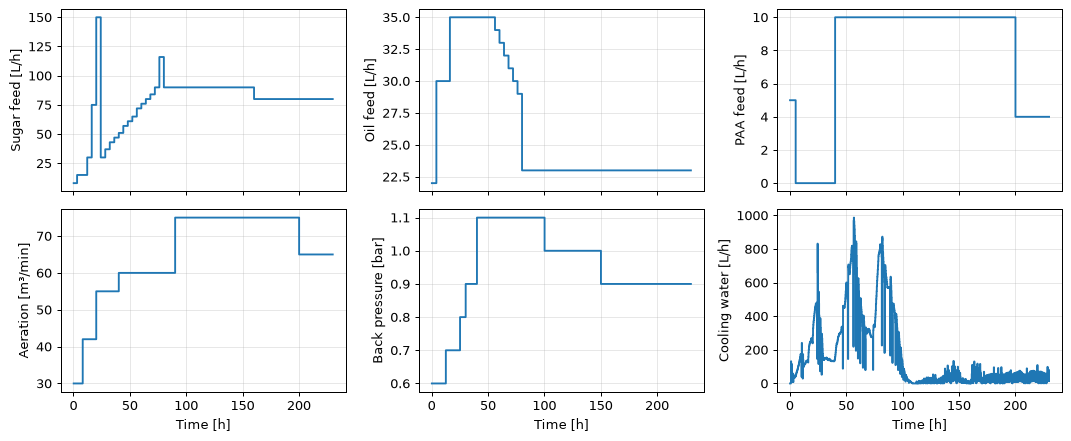

In [5]:
inputs = [
    ("Fs", "Sugar feed [L/h]"),
    ("Foil", "Oil feed [L/h]"),
    ("Fpaa", "PAA feed [L/h]"),
    ("Fg", "Aeration [m³/min]"),
    ("pressure", "Back pressure [bar]"),
    ("Fc", "Cooling water [L/h]"),
]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True)
for ax, (name, label) in zip(axes.flat, inputs):
    ax.step(result.time, result[name], where="post")
    ax.set_ylabel(label)
for ax in axes[1]:
    ax.set_xlabel("Time [h]")
fig.tight_layout()

## Batch phases

The simulator has no phase signal, but the phases are easy to derive from the batch itself:

- **Growth**: until penicillin production starts (the titre first exceeds 2 % of its maximum);
- **Growth + production**: until biomass first reaches 90 % of its maximum;
- **Stationary production**: the rest of the batch.

Change the two fractions to move the boundaries. The plots below shade the phases, the broth draws and, in a faulty
batch, the samples where the fault acts.

In [6]:
from matplotlib.patches import Patch

from penicillium import CHANNELS


def compute_phases(result, production_start=0.02, growth_end=0.9):
    t = result.time
    start = float(t[np.argmax(result["P"] >= production_start * result["P"].max())])
    end = max(float(t[np.argmax(result["X"] >= growth_end * result["X"].max())]), start)
    return {"Growth": (0.0, start), "Growth + production": (start, end), "Stationary production": (end, float(t[-1]))}


def intervals(t, mask):  # (start, end) of each run of True samples; a sample covers the 12 min before its time
    edges = np.diff(np.concatenate([[0], mask.astype(int), [0]]))
    return [(t[s] - 0.2, t[e - 1]) for s, e in zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1))]


PHASE_COLORS = {"Growth": "#dbe9f6", "Growth + production": "#fdf0d5", "Stationary production": "#e5f2df"}
phases = compute_phases(result)
draws = intervals(result.time, result["discharge"] != 0)
faults = intervals(result.time, result["Fault_ref"] == 1)


def mark(ax):
    for name, (start, end) in phases.items():
        ax.axvspan(start, end, color=PHASE_COLORS[name], zorder=0, lw=0)
    for start, end in draws:
        ax.axvspan(start, end, color="0.55", alpha=0.35, zorder=0.5, lw=0)
    for start, end in faults:
        ax.axvspan(start, end, facecolor="none", edgecolor="#c0392b", hatch="////", zorder=0.6, lw=0)


LEGEND = [Patch(color=c, label=n) for n, c in PHASE_COLORS.items()] + [
    Patch(color="0.55", alpha=0.35, label="Broth draw"),
    Patch(facecolor="none", edgecolor="#c0392b", hatch="////", label="Fault active"),
]
pd.DataFrame(phases, index=["start [h]", "end [h]"]).T.round(1)

,start [h],end [h]
Growth,0.0,28.0
Growth + production,28.0,87.8
Stationary production,87.8,230.0


## Every channel, by group

`penicillium.CHANNELS` maps every channel to its description and unit. The 55 channels fall into four groups (plus
the lab results, see [tutorial 4](04_lab_data_raman_and_noise.ipynb)):

1. **Manipulated variables**: recipe inputs and controller outputs;
2. **Online measurements**: what a plant measures continuously;
3. **Process states**: concentrations not measured online;
4. **Model internals**: the biomass regions and vacuole size classes of the morphological model.

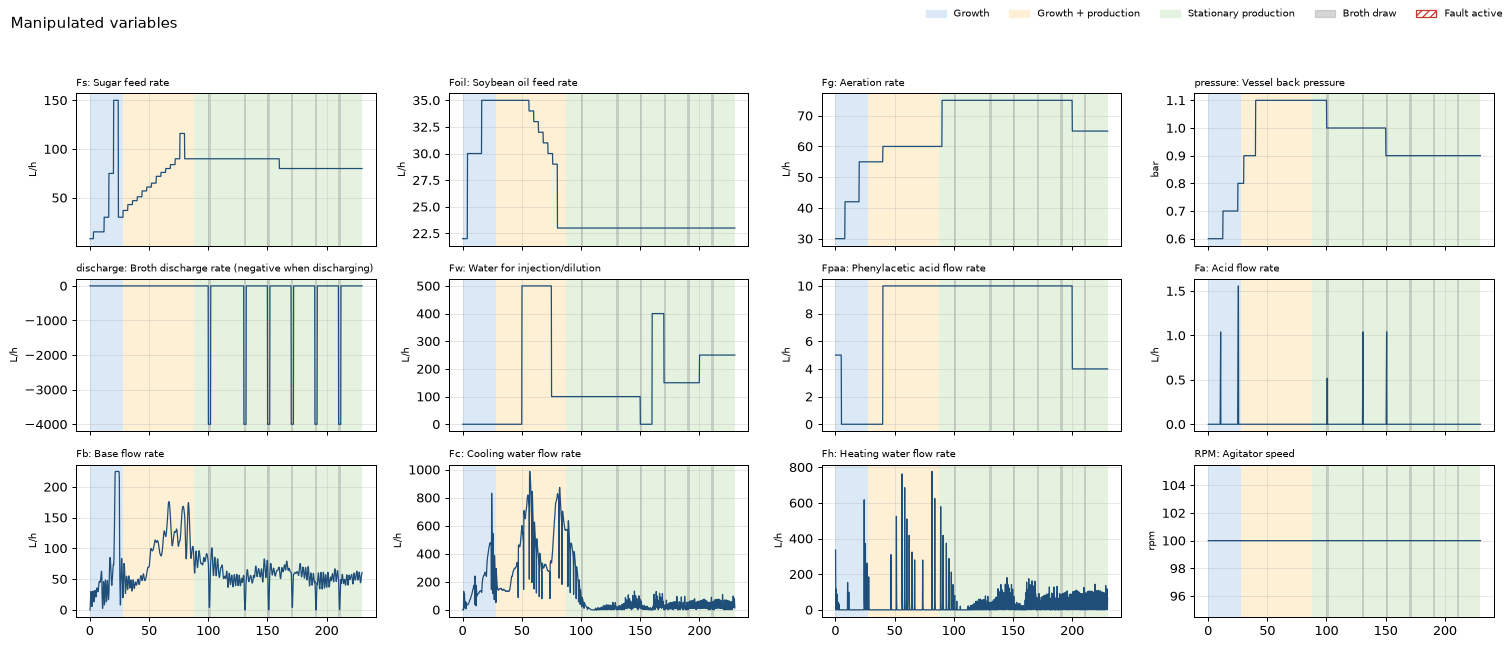

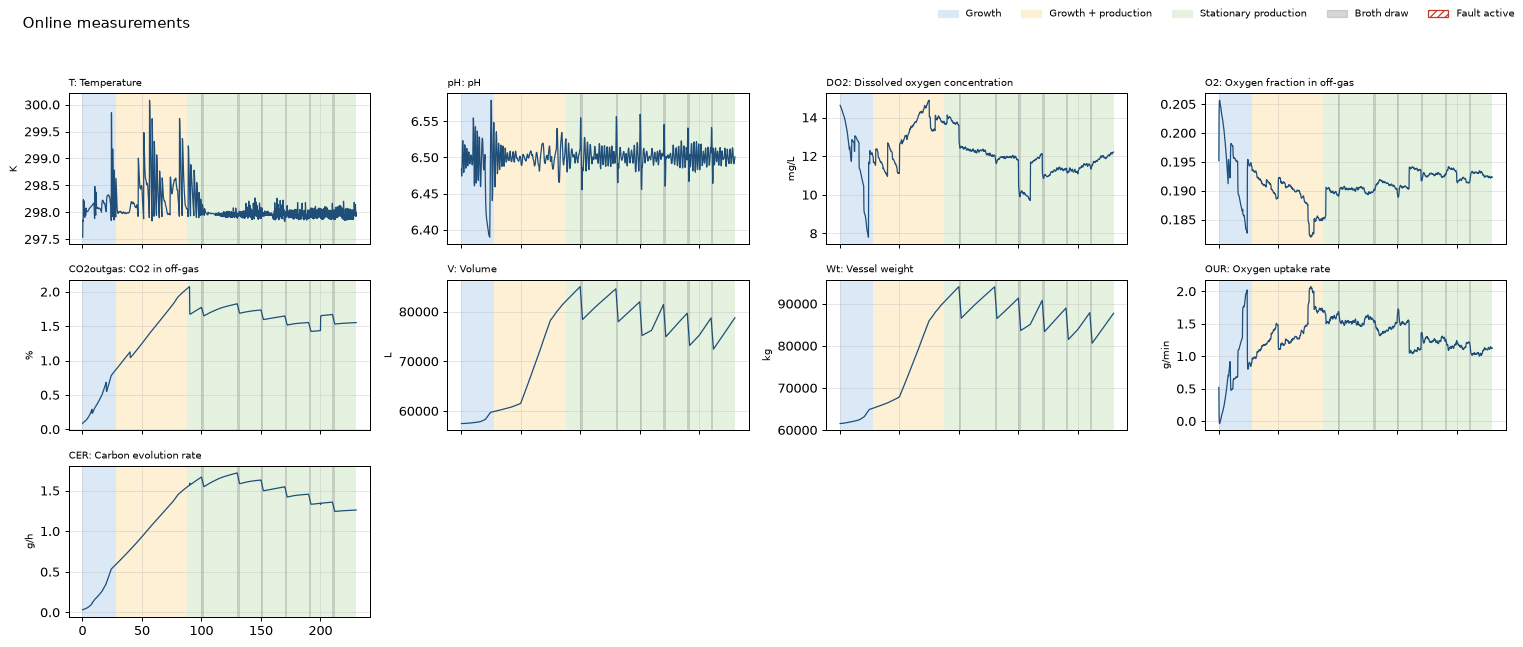

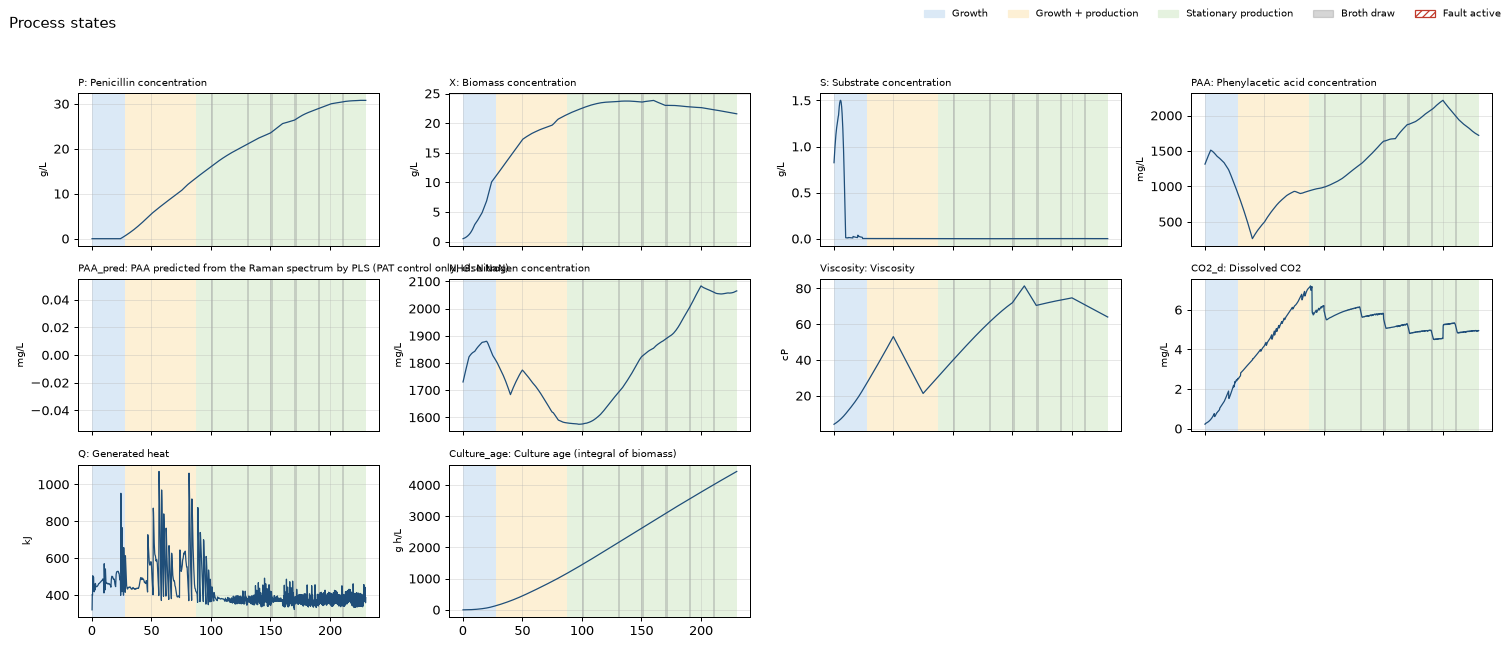

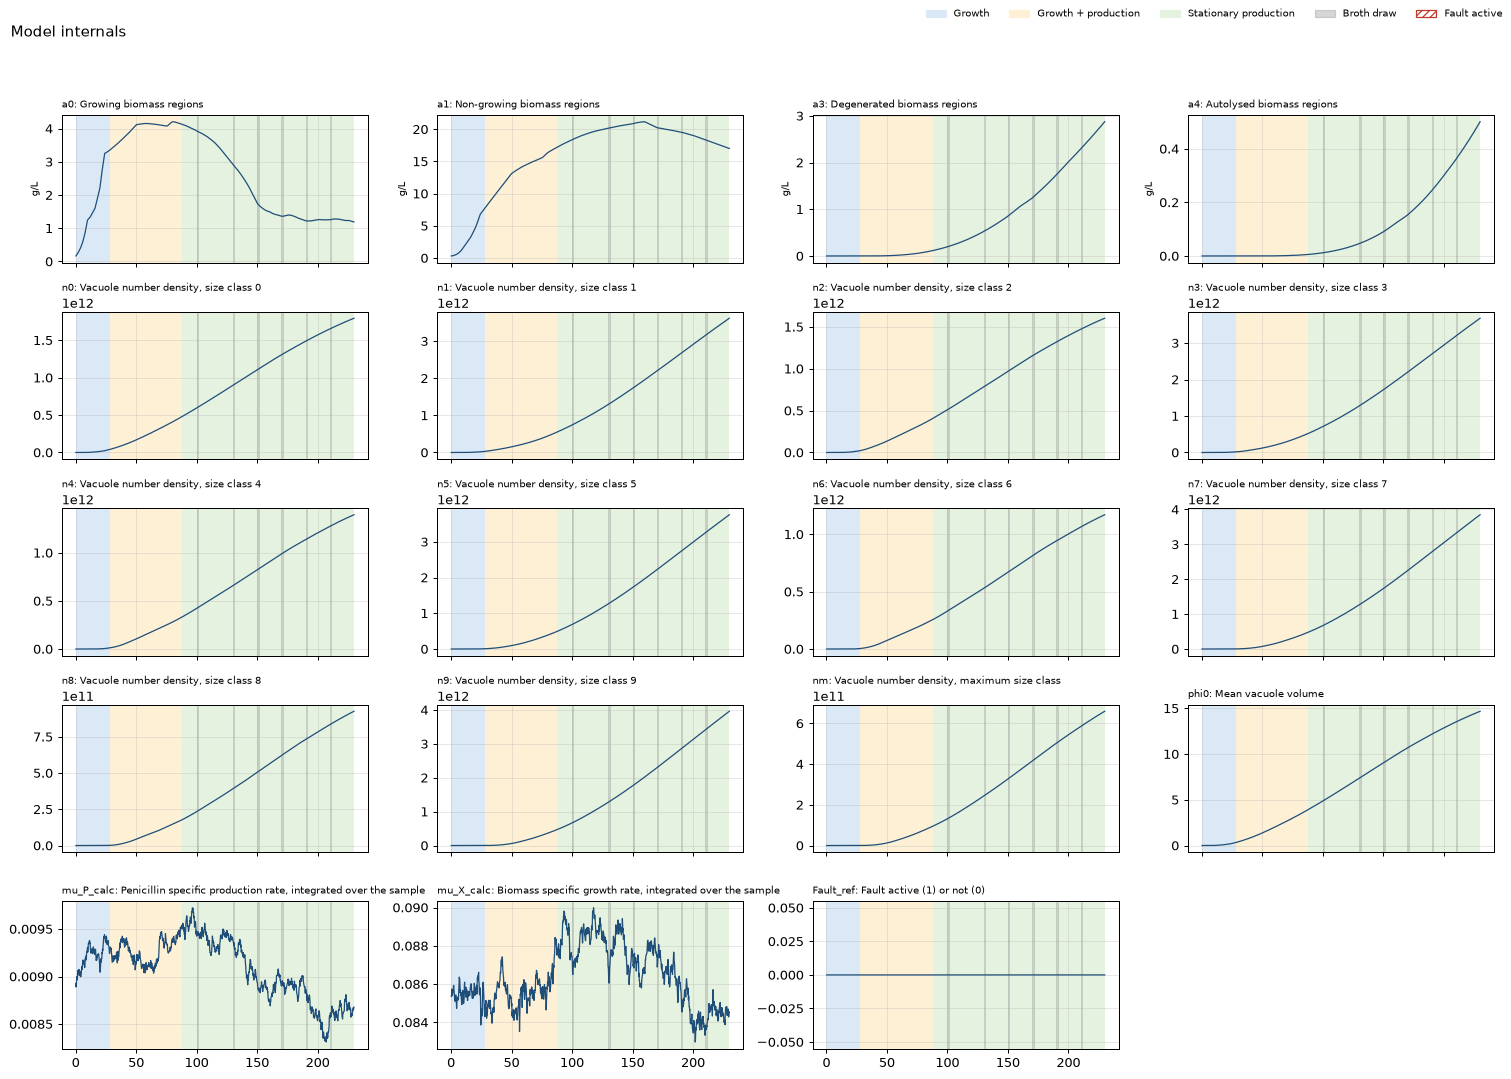

In [7]:
GROUPS = {
    "Manipulated variables": ["Fs", "Foil", "Fg", "pressure", "discharge", "Fw", "Fpaa", "Fa", "Fb", "Fc", "Fh", "RPM"],
    "Online measurements": ["T", "pH", "DO2", "O2", "CO2outgas", "V", "Wt", "OUR", "CER"],
    "Process states": ["P", "X", "S", "PAA", "PAA_pred", "NH3", "Viscosity", "CO2_d", "Q", "Culture_age"],
    "Model internals": [
        "a0",
        "a1",
        "a3",
        "a4",
        *[f"n{i}" for i in range(10)],
        "nm",
        "phi0",
        "mu_P_calc",
        "mu_X_calc",
        "Fault_ref",
    ],
}


def plot_group(title, names, ncols=4):
    nrows = -(-len(names) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 2.4 * nrows), sharex=True, squeeze=False)
    for ax, name in zip(axes.flat, names):
        mark(ax)
        ax.plot(result.time, result[name], color="#1f4e79", lw=1)
        description, unit = CHANNELS[name]
        ax.set_title(f"{name}: {description}", fontsize=8, loc="left")
        ax.set_ylabel(unit if unit != "-" else "", fontsize=8)
    for ax in axes.flat[len(names) :]:
        ax.set_visible(False)
    fig.suptitle(title, x=0.01, ha="left")
    fig.legend(handles=LEGEND, loc="upper right", ncol=len(LEGEND), fontsize=8, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.95))


for title, names in GROUPS.items():
    plot_group(title, names)

## Batch-to-batch variation

Each seed is a different batch from the same plant: initial conditions, kinetic parameters and disturbances all vary.
Here are ten batches.

count      10.0
mean     2766.0
std       719.0
min      1694.0
25%      2332.0
50%      2496.0
75%      3427.0
max      3899.0
Name: yield_kg, dtype: float64


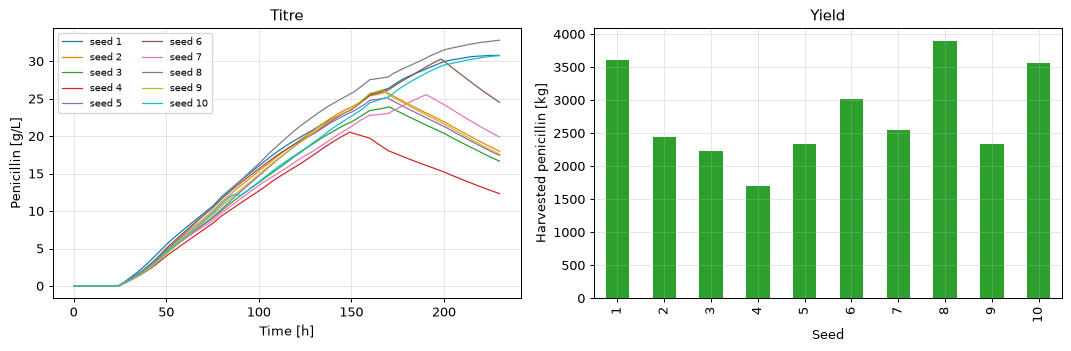

In [8]:
batches = {seed: Simulator().run(seed=seed) for seed in range(1, 11)}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
for seed, res in batches.items():
    ax1.plot(res.time, res["P"], lw=1, label=f"seed {seed}")
ax1.set(xlabel="Time [h]", ylabel="Penicillin [g/L]", title="Titre")
ax1.legend(ncol=2, fontsize=8)
yields = pd.Series({seed: res.total_yield for seed, res in batches.items()}, name="yield_kg")
yields.plot.bar(ax=ax2, color="tab:green")
ax2.set(xlabel="Seed", ylabel="Harvested penicillin [kg]", title="Yield")
fig.tight_layout()
print(yields.describe().round(0))

A spread of several hundred kilograms between batches is normal for this process. If every batch you simulate looks
the same, check that the disturbances are on (see tutorial 3).

## Save the data

In [9]:
import tempfile
from pathlib import Path

out = Path(tempfile.mkdtemp())
df.to_csv(out / "batch_seed1.csv")
print(sorted(p.name for p in out.iterdir()), f"{(out / 'batch_seed1.csv').stat().st_size / 1e6:.1f} MB")

['batch_seed1.csv'] 0.9 MB


For many batches at once, use [campaigns](05_campaigns_and_fault_detection.ipynb) or the
[command line](09_command_line.ipynb).

**Next:** [Recipes and control](02_recipes_and_control.ipynb).